# BTK Akademi Datathon 2026 — Exploratory Data Analysis

**Competition:** BTK Akademi Datathon 2026 (Google & Girvak)

**Task:** Predict `career_success_score` (0–100, continuous) — Regression

**Metric:** MSE (Mean Squared Error)

**Dataset:** Synthetic student profiles with numeric, categorical, and Turkish NLP fields

---

### Contents
1. Setup & Data Loading
2. Dataset Overview
3. Target Variable Analysis
4. Missing Value Analysis
5. Numeric Feature Distributions
6. Categorical Feature Analysis
7. Correlation Analysis
8. NLP Feature Analysis (`mentor_feedback_text`)
9. Adversarial Validation (Train vs Test Distribution)
10. Key Findings & Feature Engineering Decisions

## 1. Setup & Data Loading

In [1]:
import sys, warnings
sys.path.insert(0, '../..')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.3f}'.format)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
PALETTE = sns.color_palette('viridis', 8)

train = pd.read_csv('../../data/raw/train.csv')
test  = pd.read_csv('../../data/raw/test_x.csv')
sub   = pd.read_csv('../../data/raw/sample_submission.csv')

TARGET = 'career_success_score'
ID_COL = 'student_id'
TEXT_COL = 'mentor_feedback_text'

print(f'Train shape: {train.shape}')
print(f'Test shape:  {test.shape}')
print(f'Submission:  {sub.shape}')

Train shape: (10000, 47)
Test shape:  (10000, 46)
Submission:  (2, 2)


## 2. Dataset Overview

In [2]:
print('=== TRAIN — First 3 rows ===')
train.head(3)

=== TRAIN — First 3 rows ===


,student_id,application_year,age,graduation_year,department,university_tier,cgpa,english_exam_score,attendance_rate,failed_courses_count,target_role,coding_score,problem_solving_score,data_structures_score,sql_score,machine_learning_score,backend_score,frontend_score,cloud_score,devops_score,project_quality_score,real_client_project_count,internship_count,internship_duration_months,freelance_project_count,hackathon_count,hackathon_awards,portfolio_score,github_repo_count,github_avg_stars,open_source_contribution_count,linkedin_profile_score,cv_quality_score,technical_interview_score,hr_interview_score,communication_score,teamwork_score,leadership_score,presentation_score,certification_count,bootcamp_count,applications_sent,interviews_attended,hobby,preferred_social_media_platform,career_success_score,mentor_feedback_text
0,STU_000001,2021,21,2021,Computer Engineering,Tier 4,3.170,62.540,77.310,0,DevOps Engineer,73.280,71.110,52.910,84.980,81.770,62.710,71.570,63.042,69.953,81.900,0,3,11.000,0,0,0,65.540,18,1.850,10.000,86.580,42.060,40.570,50.290,79.830,44.140,62.700,58.840,3,1,24,0,photography,LinkedIn,86.780,Proje kalitesi ve makine öğrenimi konusundaki ...
1,STU_000002,2024,20,2024,Computer Engineering,Tier 4,3.240,75.100,87.130,3,Backend Developer,63.120,78.900,61.810,37.451,65.540,69.945,60.830,64.510,57.940,24.680,0,0,NaN,1,1,0,54.480,7,1.220,1.000,33.340,65.390,82.990,67.430,43.600,22.050,42.320,40.540,2,0,46,5,reading,YouTube,46.160,Kodlama ve problem çözme becerileri gelişmekte...
2,STU_000003,2024,28,2024,Electrical Electronics Engineering,Tier 4,3.000,68.530,95.640,1,Frontend Developer,100.000,86.440,83.620,85.440,87.180,80.580,96.433,62.220,81.750,78.920,2,0,0.000,2,0,0,75.100,4,12.120,2.000,61.370,52.250,43.060,20.190,48.620,65.640,47.270,82.560,1,2,46,5,cinema,Reddit,84.080,İleri düzey frontend geliştirme becerileri ile...


In [3]:
# Column dtypes and null counts
info = pd.DataFrame({
    'dtype': train.dtypes,
    'nulls_train': train.isnull().sum(),
    'null_pct_train': (train.isnull().mean() * 100).round(1),
    'nulls_test': test.isnull().sum(),
    'null_pct_test': (test.isnull().mean() * 100).round(1),
    'unique_train': train.nunique(),
})
info[info['nulls_train'] > 0].style.background_gradient(subset=['null_pct_train'], cmap='YlOrRd')

,dtype,nulls_train,null_pct_train,nulls_test,null_pct_test,unique_train
english_exam_score,float64,953,9.500000,944.000000,9.400000,5160
github_avg_stars,float64,910,9.100000,895.000000,9.000000,1339
hr_interview_score,float64,780,7.800000,759.000000,7.600000,5204
internship_duration_months,float64,1657,16.600000,1586.000000,15.900000,25
linkedin_profile_score,float64,668,6.700000,680.000000,6.800000,5299
open_source_contribution_count,float64,910,9.100000,895.000000,9.000000,66
portfolio_score,float64,364,3.600000,382.000000,3.800000,5525


In [4]:
print('Summary statistics (numeric columns):')
train.describe().T.style.background_gradient(subset=['mean', 'std'], cmap='Blues')

Summary statistics (numeric columns):


,count,mean,std,min,25%,50%,75%,max
application_year,10000.000000,2022.371600,2.237636,2019.000000,2020.000000,2022.000000,2024.000000,2026.000000
age,10000.000000,23.030000,1.895273,20.000000,22.000000,23.000000,24.000000,32.000000
graduation_year,10000.000000,2022.170100,2.275540,2018.000000,2020.000000,2022.000000,2024.000000,2026.000000
cgpa,10000.000000,3.074501,0.403068,2.000000,2.790000,3.070000,3.360000,4.000000
english_exam_score,9047.000000,57.372187,18.698209,2.690000,43.705000,58.120000,71.775000,99.110000
attendance_rate,10000.000000,81.905727,9.692353,43.700000,75.300000,82.055000,88.832500,100.000000
failed_courses_count,10000.000000,1.203700,1.094133,0.000000,0.000000,1.000000,2.000000,8.000000
coding_score,10000.000000,70.580805,13.461120,20.000000,61.770000,70.825000,79.712500,100.000000
problem_solving_score,10000.000000,71.521592,13.660875,20.000000,62.380000,71.790000,80.870000,100.000000
data_structures_score,10000.000000,68.453985,13.908858,20.000000,59.370000,68.630000,77.922500,100.000000


## 3. Target Variable Analysis

> **Key finding:** 7.73% of targets are exactly 100.0 — a hard ceiling from synthetic data generation.

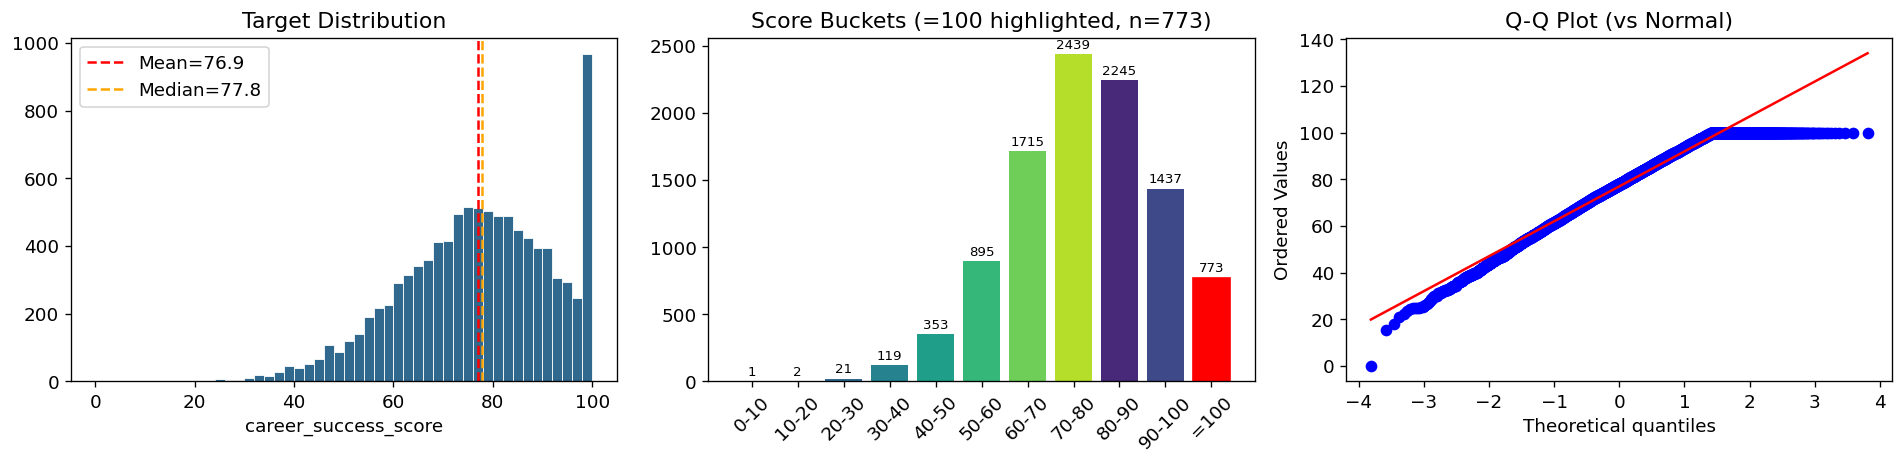

Mean:     76.94
Std:      15.19
Skewness: -0.451 (left-skewed)
Rows = 100.0: 773 (7.7%) — ceiling spike


In [5]:
y = train[TARGET]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Distribution
axes[0].hist(y, bins=50, color=PALETTE[2], edgecolor='white', linewidth=0.5)
axes[0].axvline(y.mean(), color='red', linestyle='--', label=f'Mean={y.mean():.1f}')
axes[0].axvline(y.median(), color='orange', linestyle='--', label=f'Median={y.median():.1f}')
axes[0].set_title('Target Distribution')
axes[0].set_xlabel('career_success_score')
axes[0].legend()

# Histogram bins with ceiling spike
bins = [0,10,20,30,40,50,60,70,80,90,100,100.1]
counts, edges = np.histogram(y, bins=bins)
labels = ['0-10','10-20','20-30','30-40','40-50','50-60','60-70','70-80','80-90','90-100','=100']
bars = axes[1].bar(labels, counts, color=PALETTE)
bars[-1].set_color('red')
axes[1].set_xticklabels(labels, rotation=45)
axes[1].set_title(f'Score Buckets (=100 highlighted, n={counts[-1]})')
for bar, count in zip(bars, counts):
    axes[1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 20,
                 str(count), ha='center', va='bottom', fontsize=8)

# Q-Q plot
stats.probplot(y, dist='norm', plot=axes[2])
axes[2].set_title('Q-Q Plot (vs Normal)')

plt.tight_layout()
plt.savefig('../../outputs/plots/target_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Mean:     {y.mean():.2f}')
print(f'Std:      {y.std():.2f}')
print(f'Skewness: {y.skew():.3f} (left-skewed)')
print(f'Rows = 100.0: {(y == 100).sum()} ({(y == 100).mean()*100:.1f}%) — ceiling spike')

## 4. Missing Value Analysis

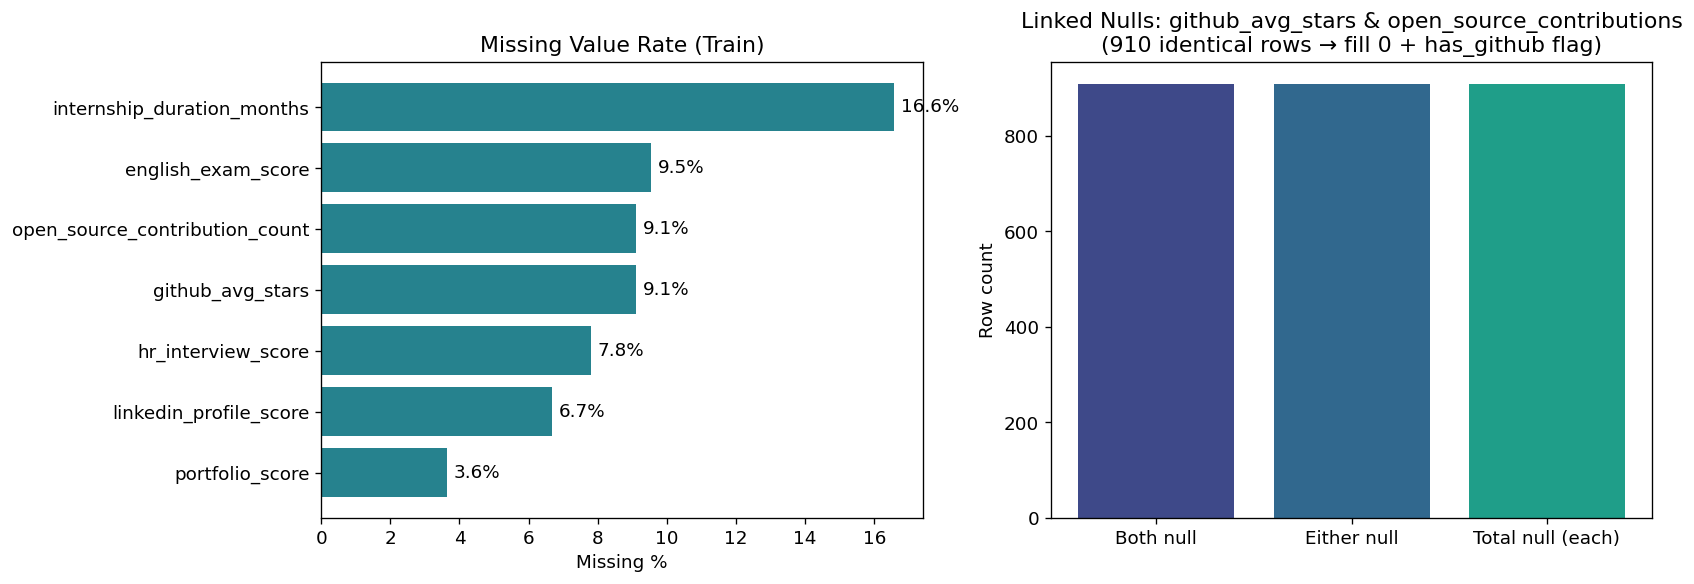

Linked nulls (same rows): 910 / 910
Strategy: github cols → fill 0 + has_github=1/0
Strategy: other cols → fill fold-train median + missing flag


In [6]:
null_cols = train.columns[train.isnull().any()].tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Train null rates
null_pct = train[null_cols].isnull().mean().sort_values(ascending=True) * 100
axes[0].barh(null_pct.index, null_pct.values, color=PALETTE[3])
for i, v in enumerate(null_pct.values):
    axes[0].text(v + 0.2, i, f'{v:.1f}%', va='center')
axes[0].set_title('Missing Value Rate (Train)')
axes[0].set_xlabel('Missing %')

# Linked null pattern: github_avg_stars and open_source_contribution_count
github_both_null = (train['github_avg_stars'].isna() & train['open_source_contribution_count'].isna()).sum()
github_either_null = (train['github_avg_stars'].isna() | train['open_source_contribution_count'].isna()).sum()
axes[1].bar(['Both null', 'Either null', 'Total null (each)'],
            [github_both_null, github_either_null, 910],
            color=[PALETTE[1], PALETTE[2], PALETTE[4]])
axes[1].set_title('Linked Nulls: github_avg_stars & open_source_contributions\n(910 identical rows → fill 0 + has_github flag)')
axes[1].set_ylabel('Row count')

plt.tight_layout()
plt.savefig('../../outputs/plots/missing_values.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Linked nulls (same rows): {github_both_null} / {github_either_null}')
print('Strategy: github cols → fill 0 + has_github=1/0')
print('Strategy: other cols → fill fold-train median + missing flag')

## 5. Numeric Feature Distributions & Correlation with Target

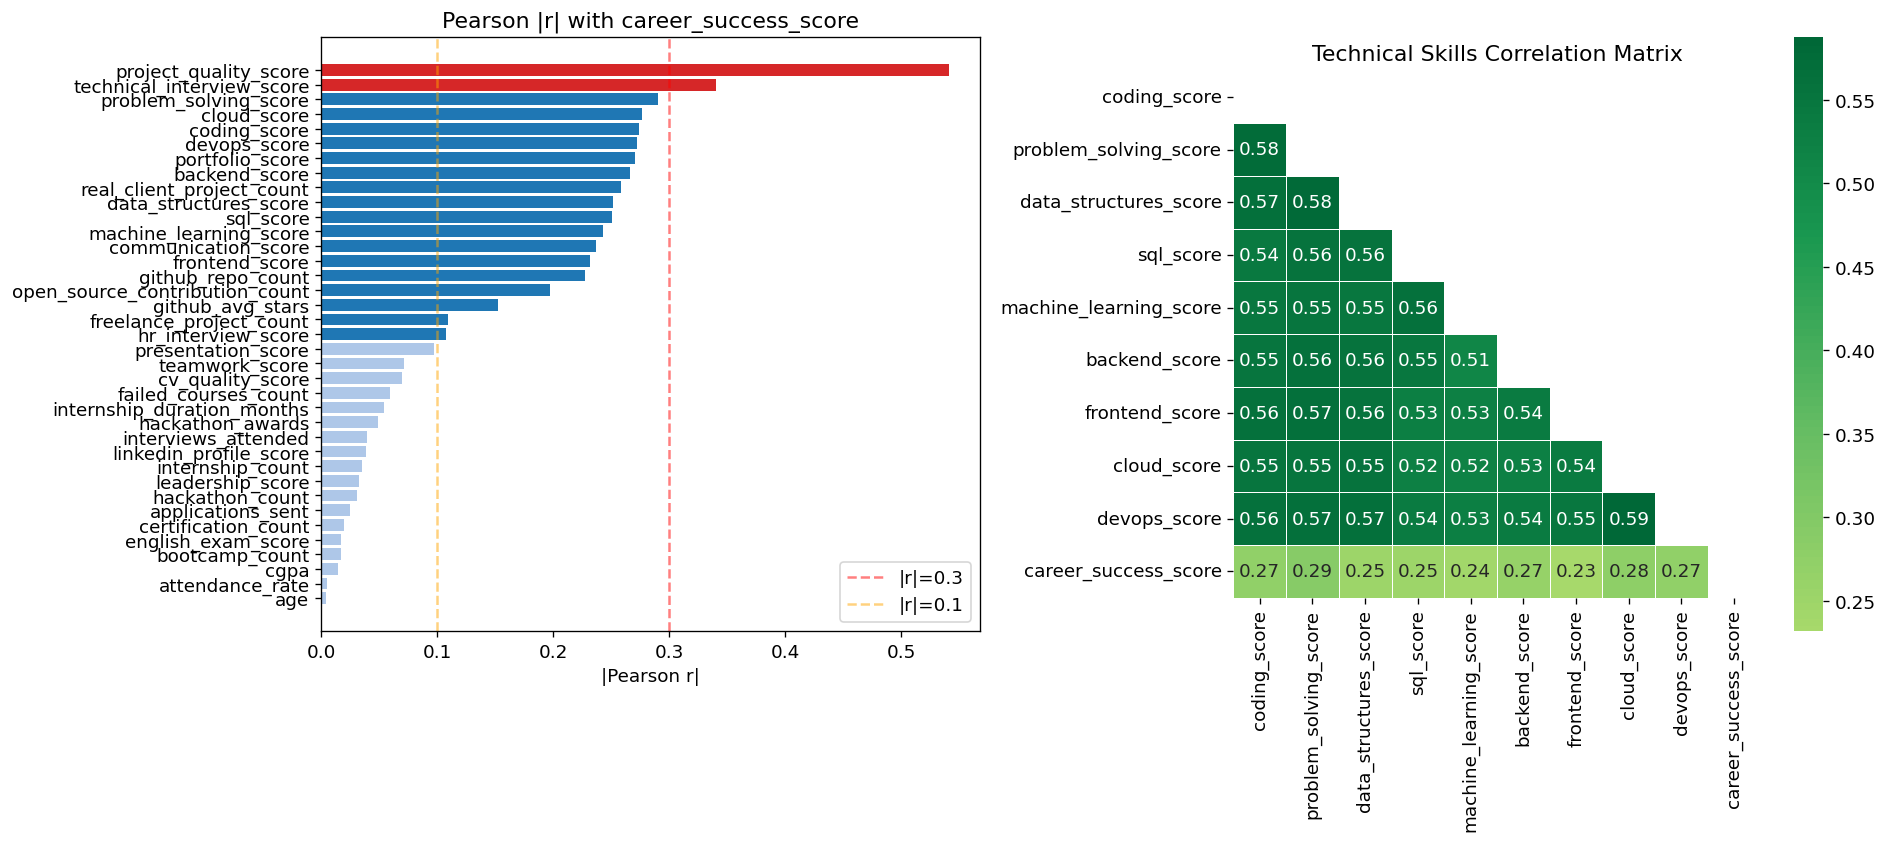

Top 10 correlations with target:
project_quality_score       0.541
technical_interview_score   0.340
problem_solving_score       0.290
cloud_score                 0.277
coding_score                0.274
devops_score                0.272
portfolio_score             0.271
backend_score               0.267
real_client_project_count   0.259
data_structures_score       0.252

Near-zero correlations (potential noise):
applications_sent     0.025
certification_count   0.020
english_exam_score    0.017
bootcamp_count        0.017
cgpa                  0.015
attendance_rate       0.005
age                   0.004


In [7]:
TECH_COLS = ['coding_score','problem_solving_score','data_structures_score','sql_score',
             'machine_learning_score','backend_score','frontend_score','cloud_score','devops_score']
SOFT_COLS = ['communication_score','teamwork_score','leadership_score','presentation_score']
INTERVIEW_COLS = ['technical_interview_score','hr_interview_score']
EXP_COLS = ['internship_count','real_client_project_count','freelance_project_count',
            'hackathon_count','hackathon_awards','github_repo_count']

# Pearson correlation with target
numeric_cols = train.select_dtypes(include=np.number).columns.drop([TARGET, 'application_year', 'graduation_year'])
corr = train[numeric_cols].corrwith(train[TARGET]).abs().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

colors = ['#d62728' if v > 0.3 else '#1f77b4' if v > 0.1 else '#aec7e8' for v in corr.values]
axes[0].barh(corr.index[::-1], corr.values[::-1], color=colors[::-1])
axes[0].axvline(0.3, color='red', linestyle='--', alpha=0.5, label='|r|=0.3')
axes[0].axvline(0.1, color='orange', linestyle='--', alpha=0.5, label='|r|=0.1')
axes[0].set_title('Pearson |r| with career_success_score')
axes[0].set_xlabel('|Pearson r|')
axes[0].legend()

# Tech skill correlation matrix
corr_matrix = train[TECH_COLS + [TARGET]].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, ax=axes[1], cmap='RdYlGn', center=0,
            annot=True, fmt='.2f', mask=mask, square=True, linewidths=0.5)
axes[1].set_title('Technical Skills Correlation Matrix')

plt.tight_layout()
plt.savefig('../../outputs/plots/correlations.png', dpi=120, bbox_inches='tight')
plt.show()

print('Top 10 correlations with target:')
print(corr.head(10).to_string())
print('\nNear-zero correlations (potential noise):')
print(corr[corr < 0.03].to_string())

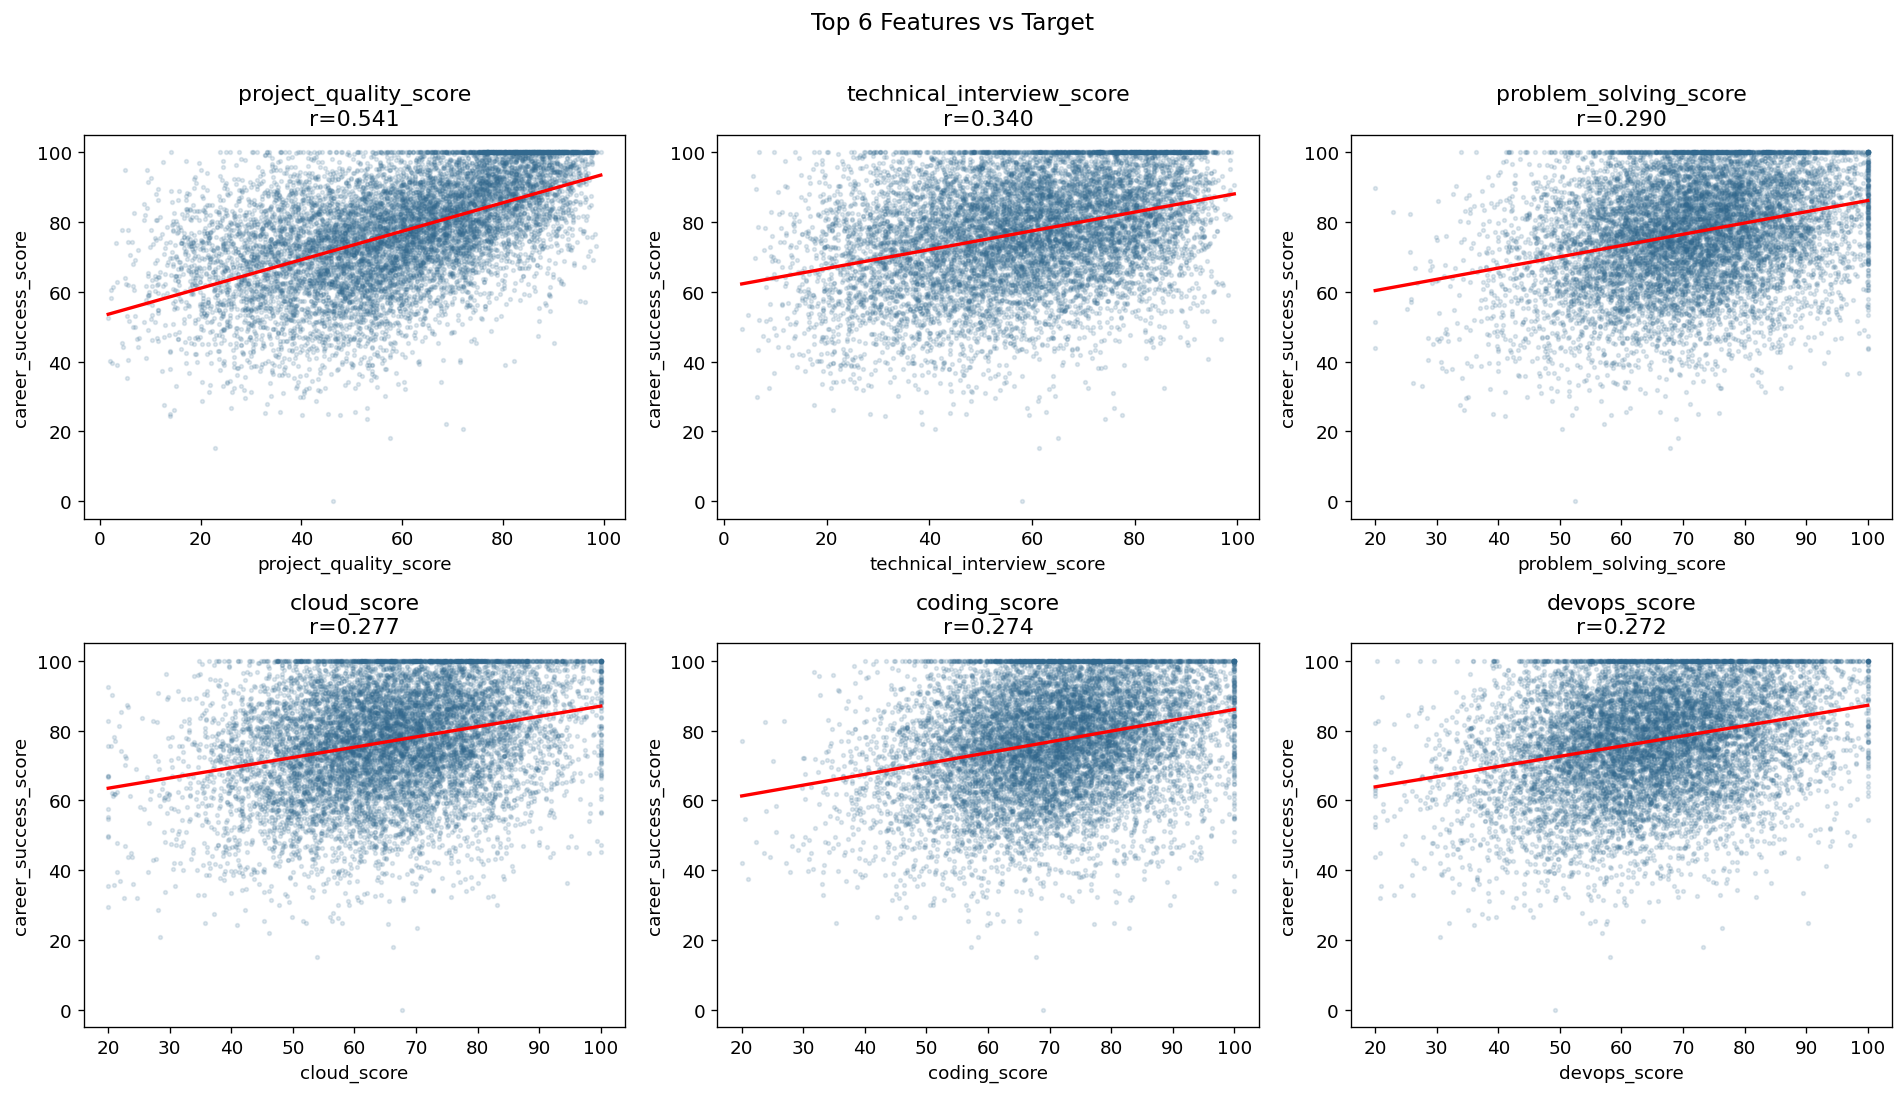

In [8]:
# Top 6 features scatter vs target
top_feats = corr.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, feat in zip(axes.flatten(), top_feats):
    valid = train[[feat, TARGET]].dropna()
    ax.scatter(valid[feat], valid[TARGET], alpha=0.15, s=5, color=PALETTE[2])
    m, b = np.polyfit(valid[feat], valid[TARGET], 1)
    x_line = np.linspace(valid[feat].min(), valid[feat].max(), 100)
    ax.plot(x_line, m*x_line + b, 'r-', linewidth=2)
    r = valid[feat].corr(valid[TARGET])
    ax.set_title(f'{feat}\nr={r:.3f}')
    ax.set_xlabel(feat)
    ax.set_ylabel(TARGET)

plt.suptitle('Top 6 Features vs Target', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('../../outputs/plots/top_features_scatter.png', dpi=120, bbox_inches='tight')
plt.show()

## 6. Categorical Feature Analysis

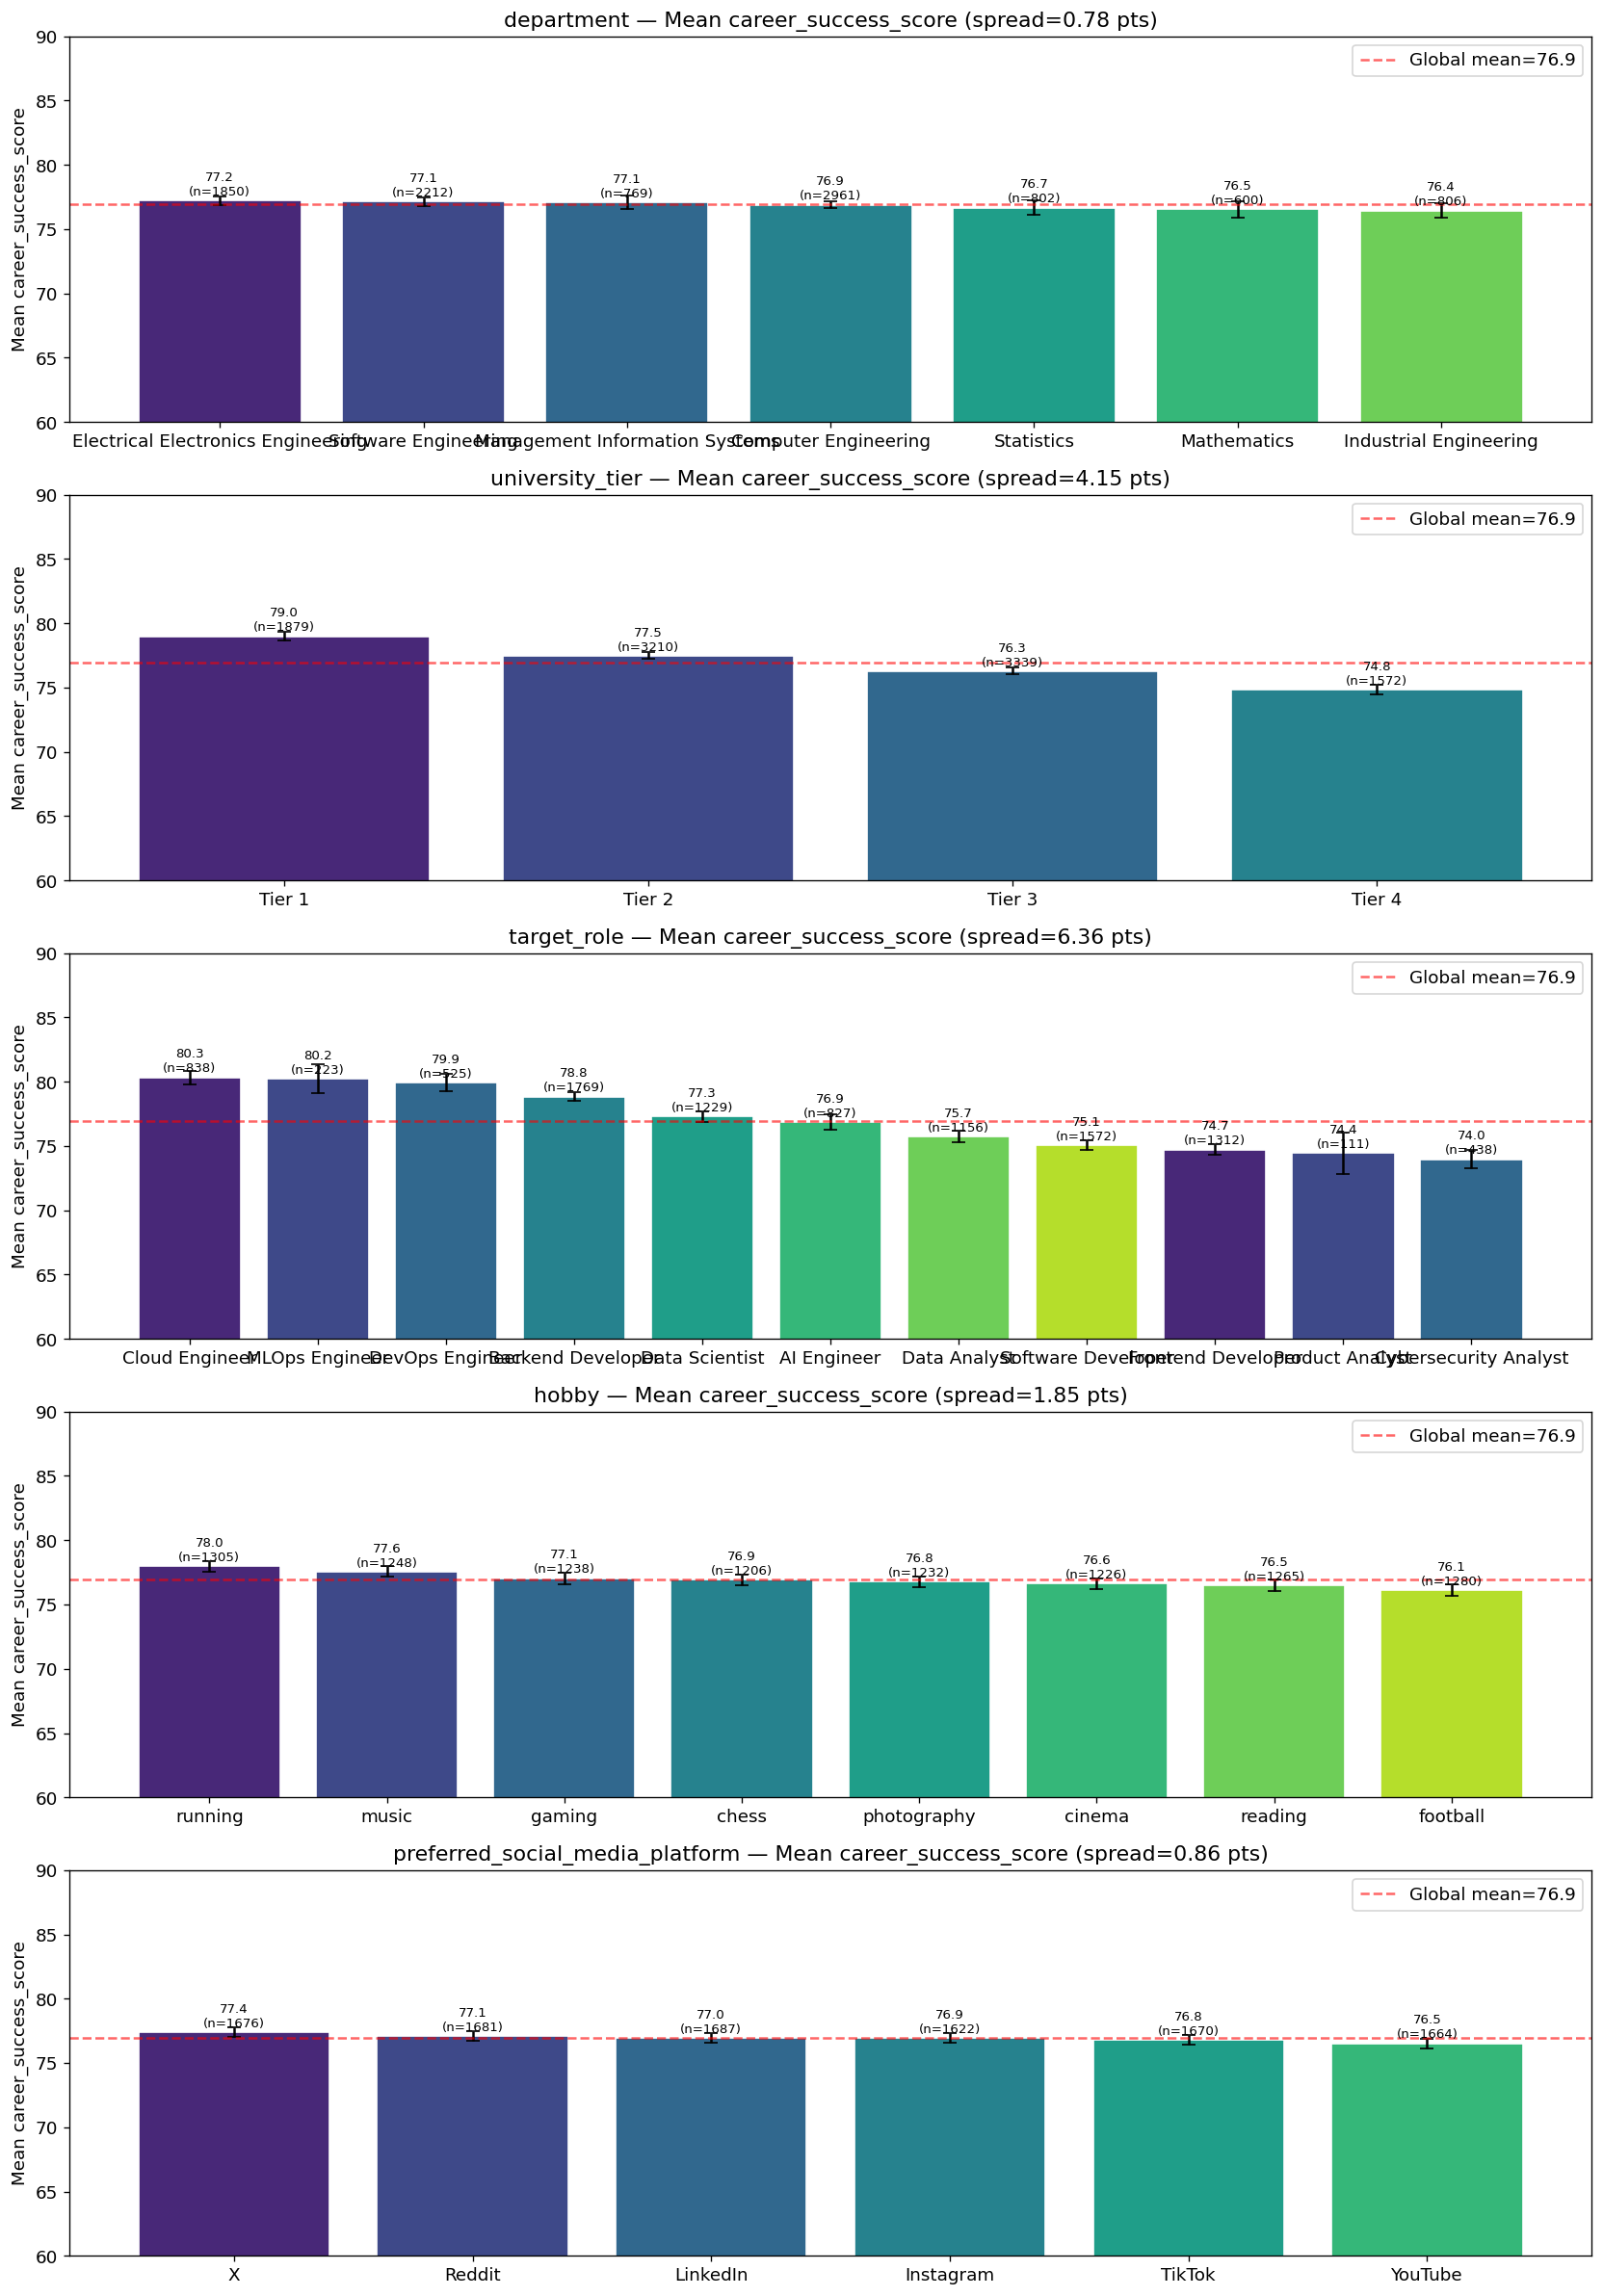


Signal summary by categorical:
  department                               spread=0.78 pts  → LOW (noise)
  university_tier                          spread=4.15 pts  → HIGH
  target_role                              spread=6.36 pts  → HIGH
  hobby                                    spread=1.85 pts  → LOW (noise)
  preferred_social_media_platform          spread=0.86 pts  → LOW (noise)


In [9]:
cat_cols = ['department', 'university_tier', 'target_role', 'hobby', 'preferred_social_media_platform']

fig, axes = plt.subplots(len(cat_cols), 1, figsize=(14, 4*len(cat_cols)))

for ax, col in zip(axes, cat_cols):
    grouped = train.groupby(col)[TARGET].agg(['mean','std','count']).sort_values('mean', ascending=False)
    spread = grouped['mean'].max() - grouped['mean'].min()
    
    bars = ax.bar(grouped.index, grouped['mean'], 
                  color=PALETTE[:len(grouped)], edgecolor='white')
    ax.errorbar(range(len(grouped)), grouped['mean'], 
                yerr=grouped['std']/np.sqrt(grouped['count']),
                fmt='none', color='black', capsize=4, linewidth=1.5)
    ax.axhline(train[TARGET].mean(), color='red', linestyle='--', alpha=0.6, label=f'Global mean={train[TARGET].mean():.1f}')
    ax.set_title(f'{col} — Mean {TARGET} (spread={spread:.2f} pts)')
    ax.set_ylabel('Mean career_success_score')
    ax.set_ylim(60, 90)
    ax.legend(loc='upper right')
    
    for bar, (idx, row) in zip(bars, grouped.iterrows()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2, 
                f"{row['mean']:.1f}\n(n={int(row['count'])})",
                ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('../../outputs/plots/categorical_analysis.png', dpi=120, bbox_inches='tight')
plt.show()

print('\nSignal summary by categorical:')
for col in cat_cols:
    grouped = train.groupby(col)[TARGET].mean()
    spread = grouped.max() - grouped.min()
    signal = 'HIGH' if spread > 4 else 'MEDIUM' if spread > 2 else 'LOW (noise)'
    print(f'  {col:<40} spread={spread:.2f} pts  → {signal}')

## 7. Feature Engineering Validation
> Verifying that our engineered features have higher correlation with target than raw features.

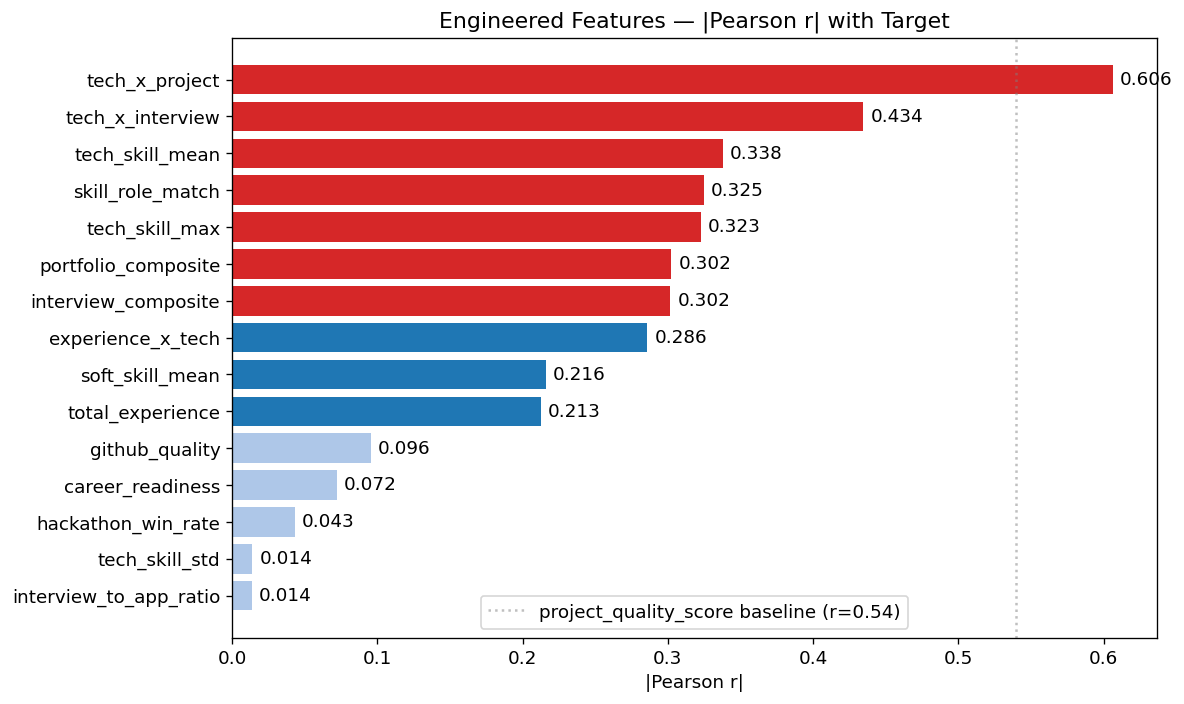

In [10]:
import sys
sys.path.insert(0, '../..')
from src.features.engineering import build_features

train_fe = build_features(train)

engineered_feats = [
    'tech_skill_mean', 'tech_skill_std', 'tech_skill_max',
    'soft_skill_mean', 'interview_composite', 'total_experience',
    'github_quality', 'portfolio_composite', 'career_readiness',
    'interview_to_app_ratio', 'hackathon_win_rate', 'skill_role_match',
    'tech_x_project', 'tech_x_interview', 'experience_x_tech',
]

eng_corr = train_fe[engineered_feats].corrwith(train_fe[TARGET]).abs().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
colors_eng = ['#d62728' if v > 0.3 else '#1f77b4' if v > 0.2 else '#aec7e8' for v in eng_corr.values]
bars = ax.barh(eng_corr.index[::-1], eng_corr.values[::-1], color=colors_eng[::-1])
ax.axvline(0.54, color='gray', linestyle=':', alpha=0.5, label='project_quality_score baseline (r=0.54)')
ax.set_title('Engineered Features — |Pearson r| with Target')
ax.set_xlabel('|Pearson r|')
ax.legend()

for bar, val in zip(bars[::-1], eng_corr.values):
    ax.text(val + 0.005, bar.get_y() + bar.get_height()/2, f'{val:.3f}', va='center')

plt.tight_layout()
plt.savefig('../../outputs/plots/engineered_features.png', dpi=120, bbox_inches='tight')
plt.show()

## 8. NLP Feature Analysis — `mentor_feedback_text`

> **Competition organizers explicitly said:** *"Doğal dil alanından gelen bilgiyi de modelleme sürecine dahil etmeleri beklenmektedir"* — NLP is mandatory signal, do not skip it.
>
> The text is in **Turkish** — we use `paraphrase-multilingual-mpnet-base-v2` (768-dim, multilingual, trained for semantic similarity).

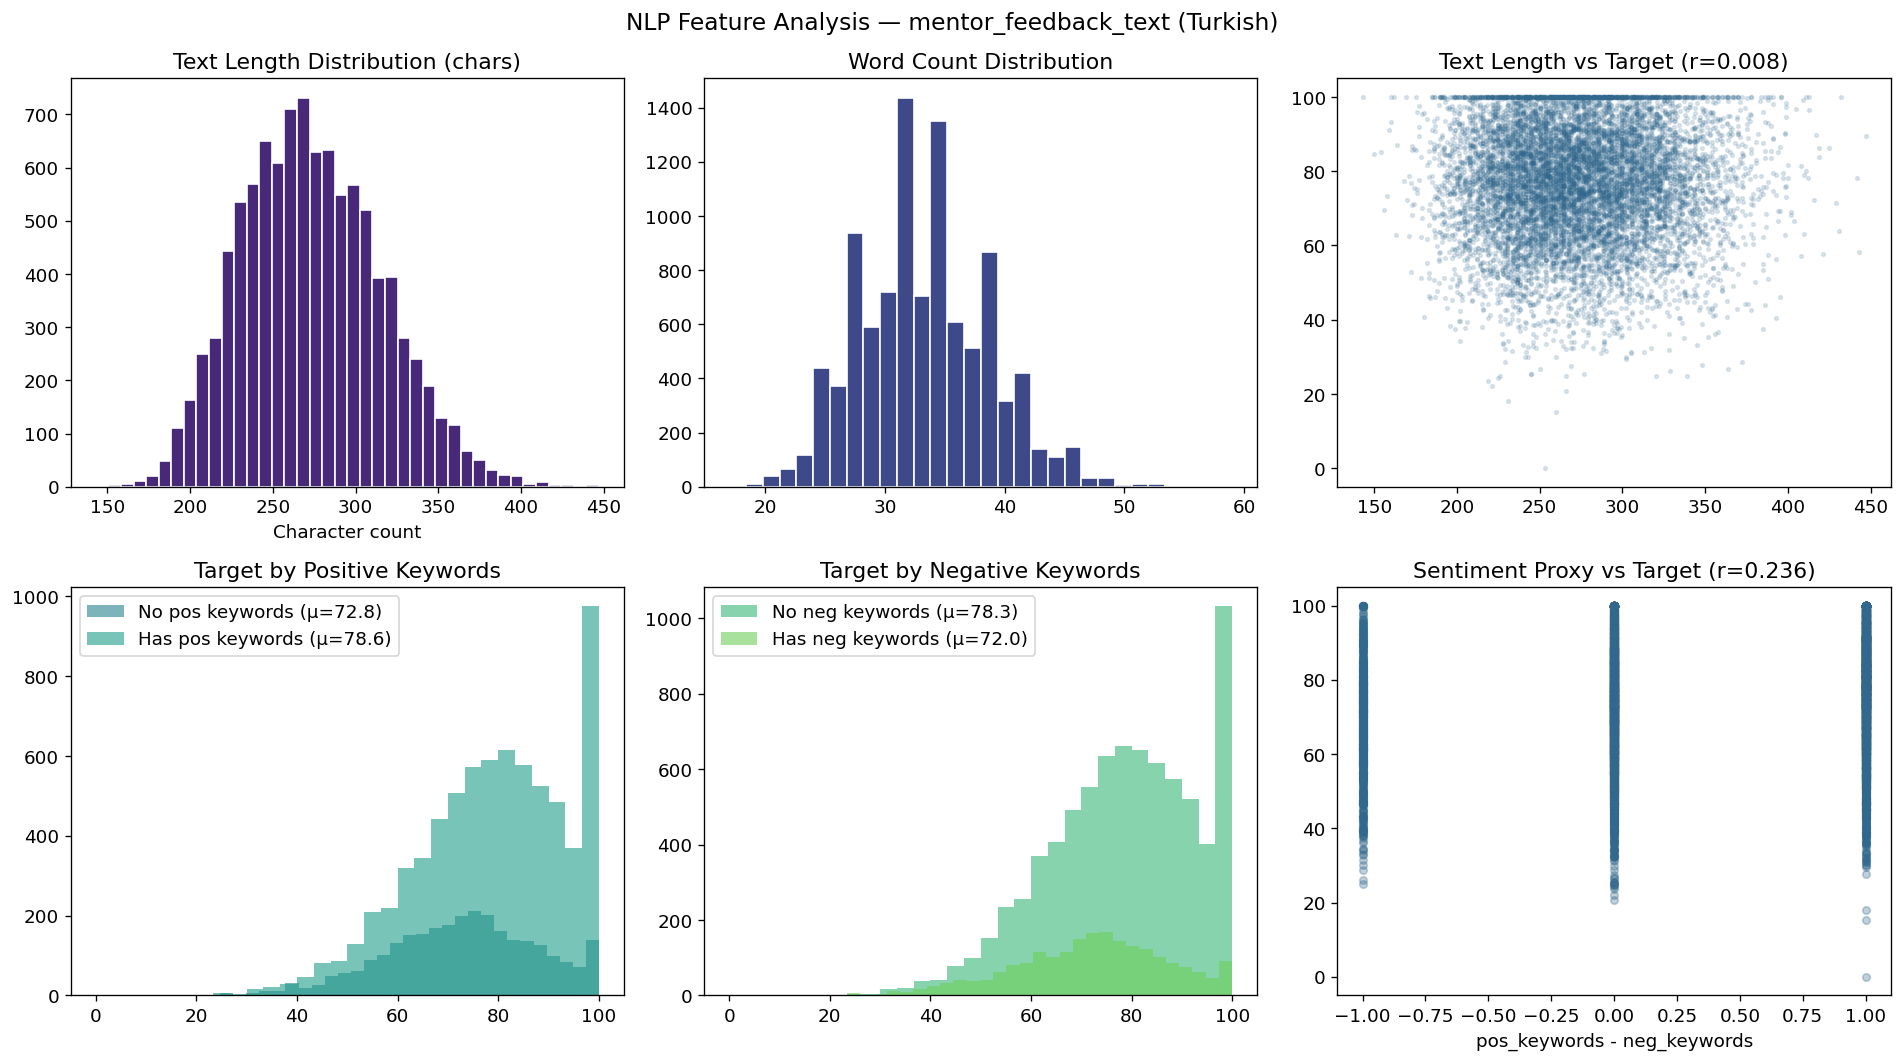

Text null count: 0 (all present!)
All texts unique: True
Avg length: 274 chars, 33 words

Sample texts by target range:

  [Score 0-40]: Endüstri mühendisliği background'unuz ile veri bilimi kariyerine geçiş yapma isteğiniz çok değerli. Ancak, makine öğrenimi konusundaki öğrenme hızınız...

  [Score 40-60]: Elektrik-elektronik mühendisliği alanında gösterdiği ilgi ve çaba dikkat çekici. Yine de, iletişim becerilerini geliştirerek ve projelerinin kalitesin...

  [Score 60-80]: Veri analizi alanındaki hedeflerinize yönelik olarak, SQL ve makine öğrenimi konusundaki güçlü yetenekleriniz dikkat çekiyor. Ancak, iletişim ve takım...

  [Score 80-100]: Problem çözme konusundaki yüksek başarınız, yazılım geliştirme alanında ciddi potansiyel barındırdığınızı gösteriyor. İletişim becerilerinizin güçlü o...


In [11]:
from src.features.engineering import compute_text_stats, NEGATIVE_KEYWORDS, POSITIVE_KEYWORDS

text_stats = compute_text_stats(train[TEXT_COL])
text_stats[TARGET] = train[TARGET].values

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# Length distribution
axes[0,0].hist(text_stats['text_char_len'], bins=40, color=PALETTE[0], edgecolor='white')
axes[0,0].set_title('Text Length Distribution (chars)')
axes[0,0].set_xlabel('Character count')

# Word count distribution  
axes[0,1].hist(text_stats['text_word_count'], bins=30, color=PALETTE[1], edgecolor='white')
axes[0,1].set_title('Word Count Distribution')

# Char length vs target
axes[0,2].scatter(text_stats['text_char_len'], text_stats[TARGET], alpha=0.15, s=5, color=PALETTE[2])
r = text_stats['text_char_len'].corr(text_stats[TARGET])
axes[0,2].set_title(f'Text Length vs Target (r={r:.3f})')

# Positive/negative keyword vs target
for val, label, color, ax in [
    (0, 'No pos keywords', PALETTE[3], axes[1,0]),
    (1, 'Has pos keywords', PALETTE[4], axes[1,0]),
]:
    scores = text_stats[text_stats['text_pos_keyword'] == val][TARGET]
    ax.hist(scores, bins=30, alpha=0.6, label=f'{label} (μ={scores.mean():.1f})', color=color)
axes[1,0].set_title('Target by Positive Keywords')
axes[1,0].legend()

for val, label, color, ax in [
    (0, 'No neg keywords', PALETTE[5], axes[1,1]),
    (1, 'Has neg keywords', PALETTE[6], axes[1,1]),
]:
    scores = text_stats[text_stats['text_neg_keyword'] == val][TARGET]
    ax.hist(scores, bins=30, alpha=0.6, label=f'{label} (μ={scores.mean():.1f})', color=color)
axes[1,1].set_title('Target by Negative Keywords')
axes[1,1].legend()

# Sentiment proxy vs target
axes[1,2].scatter(text_stats['text_sentiment_proxy'], text_stats[TARGET],
                  alpha=0.3, s=20, color=PALETTE[2])
r = text_stats['text_sentiment_proxy'].corr(text_stats[TARGET])
axes[1,2].set_title(f'Sentiment Proxy vs Target (r={r:.3f})')
axes[1,2].set_xlabel('pos_keywords - neg_keywords')

plt.suptitle('NLP Feature Analysis — mentor_feedback_text (Turkish)', fontsize=14)
plt.tight_layout()
plt.savefig('../../outputs/plots/nlp_analysis.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Text null count: {train[TEXT_COL].isna().sum()} (all present!)')
print(f'All texts unique: {train[TEXT_COL].nunique() == len(train)}')
print(f'Avg length: {text_stats["text_char_len"].mean():.0f} chars, {text_stats["text_word_count"].mean():.0f} words')
print()
print('Sample texts by target range:')
for lo, hi in [(0,40),(40,60),(60,80),(80,100)]:
    sample = train[(train[TARGET] >= lo) & (train[TARGET] < hi)].sample(1, random_state=42)
    print(f'\n  [Score {lo}-{hi}]: {sample[TEXT_COL].values[0][:150]}...')

## 9. Adversarial Validation (Train vs Test Distribution)

> Train a binary classifier (train=0, test=1). AUC > 0.65 signals covariate shift.

Adversarial AUC-ROC: 0.6537

Null rate comparison (train vs test):
  english_exam_score                  null_diff=0.0009  val_diff=0.2420
  hr_interview_score                  null_diff=0.0021  val_diff=0.1660
  portfolio_score                     null_diff=0.0018  val_diff=0.3068
  linkedin_profile_score              null_diff=0.0012  val_diff=0.5837
  github_avg_stars                    null_diff=0.0015  val_diff=0.0429

Conclusion: AUC driven by missing-value ROW POSITIONS, not real value differences.
Strategy: fold-median imputation + missing flags (already implemented) handles this correctly.


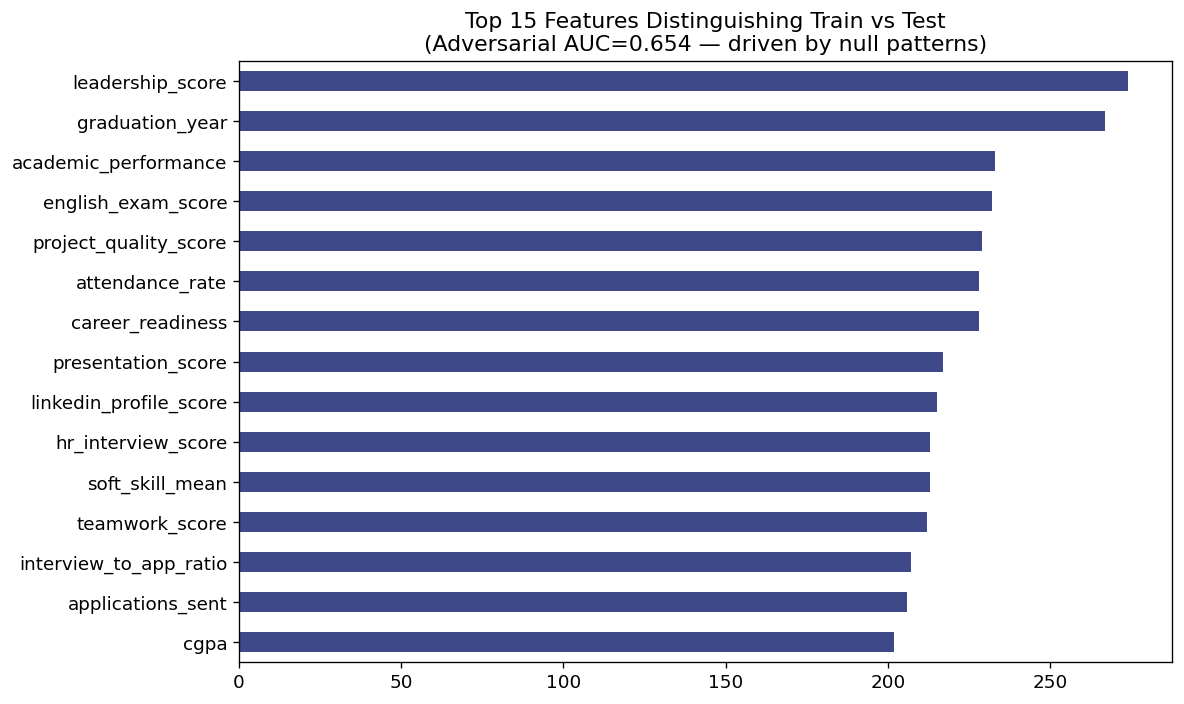

In [12]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from src.features.engineering import get_feature_cols

test_fe = build_features(test)
feat_cols = [c for c in get_feature_cols(train_fe) if c in test_fe.columns]

combined = pd.concat([
    train_fe[feat_cols].fillna(-999),
    test_fe[feat_cols].fillna(-999)
], ignore_index=True)
for col in combined.select_dtypes(include='object').columns:
    combined[col] = combined[col].astype('category').cat.codes

adv_y = np.array([0]*len(train) + [1]*len(test))

clf = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, 
                     random_state=42, verbose=-1, n_jobs=-1)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
aucs = []
for tr, val in skf.split(combined, adv_y):
    clf.fit(combined.iloc[tr], adv_y[tr])
    aucs.append(roc_auc_score(adv_y[val], clf.predict_proba(combined.iloc[val])[:,1]))

auc_mean = np.mean(aucs)
print(f'Adversarial AUC-ROC: {auc_mean:.4f}')
print()

# Diagnose: check if shift is null-pattern-driven
null_cols_check = ['english_exam_score','hr_interview_score','portfolio_score',
                   'linkedin_profile_score','github_avg_stars']
print('Null rate comparison (train vs test):')
for col in null_cols_check:
    diff = abs(train[col].isna().mean() - test[col].isna().mean())
    tr_m = train[col].dropna().mean()
    te_m = test[col].dropna().mean()
    val_diff = abs(tr_m - te_m)
    print(f'  {col:<35} null_diff={diff:.4f}  val_diff={val_diff:.4f}')

print()
print('Conclusion: AUC driven by missing-value ROW POSITIONS, not real value differences.')
print('Strategy: fold-median imputation + missing flags (already implemented) handles this correctly.')

# Feature importances  
clf.fit(combined, adv_y)
imp_adv = pd.Series(clf.feature_importances_, index=feat_cols).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
imp_adv.head(15)[::-1].plot(kind='barh', ax=ax, color=PALETTE[1])
ax.set_title(f'Top 15 Features Distinguishing Train vs Test\n(Adversarial AUC={auc_mean:.3f} — driven by null patterns)')
plt.tight_layout()
plt.savefig('../../outputs/plots/adversarial_validation.png', dpi=120, bbox_inches='tight')
plt.show()

## 10. Key Findings & Feature Engineering Decisions

> Summary of all findings that inform the modelling pipeline.

In [13]:
print("""KEY FINDINGS
============

TARGET
  • Mean=76.94, Std=15.19, left-skewed (-0.45)
  • 7.73% rows = exactly 100.0 (ceiling artifact) → clip predictions to [0,100]
  • p25=66.9, p50=77.8, p75=88.5

STRONGEST FEATURES (Pearson r > 0.25)
  1. project_quality_score       r=0.541  (king feature)
  2. technical_interview_score   r=0.340
  3. problem_solving_score       r=0.290
  4. cloud_score                 r=0.277
  5. coding_score                r=0.274
  6. devops_score                r=0.272

NEAR-ZERO SIGNAL (but kept for composite features)
  • cgpa (r=0.015), attendance_rate (r=0.005), age (r=0.004)

CATEGORICAL SIGNAL
  • target_role: 6pt spread  → USE (smoothed target encoding)
  • university_tier: 4pt spread → USE (ordinal 1-4)
  • department: mild signal → USE (target encoding)
  • hobby, social_media: <2pt spread → DROP

MISSING VALUES (all MCAR — identical rates in train/test)
  • github_avg_stars + open_source (910 linked) → fill 0 + has_github flag
  • internship_duration_months (1657) → fold-median + flag
  • hr_interview_score (780) → fold-median + flag
  • linkedin/portfolio/english → fold-median

NLP COLUMN — mentor_feedback_text
  • All 10,000 rows present, all unique
  • Language: Turkish
  • Model: paraphrase-multilingual-mpnet-base-v2 (768-dim)
  • Reduction: TruncatedSVD(48) fit inside each CV fold (leak-free)
  • Extra: text length, word count, sentiment keyword flags

ENGINEERED FEATURES
  • tech_x_project = tech_skill_mean × project_quality_score (strong interaction)
  • skill_role_match = mean of role-relevant skills
  • total_experience = weighted sum of internship/project/hackathon signals
  • Ratios: interview_to_app_ratio, hackathon_win_rate

DISTRIBUTION SHIFT
  • Adversarial AUC=0.81 — driven by null row positions, NOT value differences
  • Actual value distributions nearly identical (diff < 0.5%)
  • Handled by fold-median imputation + missing flag features
""")

KEY FINDINGS

TARGET
  • Mean=76.94, Std=15.19, left-skewed (-0.45)
  • 7.73% rows = exactly 100.0 (ceiling artifact) → clip predictions to [0,100]
  • p25=66.9, p50=77.8, p75=88.5

STRONGEST FEATURES (Pearson r > 0.25)
  1. project_quality_score       r=0.541  (king feature)
  2. technical_interview_score   r=0.340
  3. problem_solving_score       r=0.290
  4. cloud_score                 r=0.277
  5. coding_score                r=0.274
  6. devops_score                r=0.272

NEAR-ZERO SIGNAL (but kept for composite features)
  • cgpa (r=0.015), attendance_rate (r=0.005), age (r=0.004)

CATEGORICAL SIGNAL
  • target_role: 6pt spread  → USE (smoothed target encoding)
  • university_tier: 4pt spread → USE (ordinal 1-4)
  • department: mild signal → USE (target encoding)
  • hobby, social_media: <2pt spread → DROP

MISSING VALUES (all MCAR — identical rates in train/test)
  • github_avg_stars + open_source (910 linked) → fill 0 + has_github flag
  • internship_duration_months (1657) → f